# Stage 1 feature screening (before training)

This notebook screens the 24 candidate features in `question_b_feature_dictionary.csv` **before** any LightGBM or XGBoost model is trained. Each feature is labelled **keep** or **exclude**, and the excluded features are dropped before the data is saved.

Stage 1 has three checks:

| Check | Question it answers | Possible outcome |
|---|---|---|
| 1. Leakage and availability | Is the value known when the forecast is made (00:00, day ahead)? | Exclude |
| 2. Data quality | Is the feature populated, varied, trustworthy and present in every split? | Exclude or fix |
| 3. Redundancy | Does the feature repeat information another feature already carries? | Exclude |

**Why screen before training rather than let the model decide?**
- A leaky feature looks extremely important to the model and inflates accuracy, so importance scores after training would **reward** the very features that must be removed.
- A broken or duplicated feature still gets used by the trees. It dilutes the importance of the real signal, which makes Stage 2 harder to interpret.
- These checks don't need a model. They use the dictionary, the training data and simple statistics, so the decisions are transparent and easy to defend.

**Only the training split is used to judge relationships** (correlation). If validation or test data influenced which features are kept, the later accuracy scores would be optimistic. Validation and test are used in one place only: Check 2d, which asks whether each split contains values the training data never saw. That check doesn't use the target.

**Outputs**
- `Output/question_b_model_data_screened.parquet`: the modelling data with only the kept features (plus id, split, filter and target columns), and the Floor 5 zone 1 indoor readings masked.
- `Output/question_b_feature_dictionary_screened.csv`: the dictionary with a Stage 1 decision and reason for every column, and the M1–M4 sets updated.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

DATA_DIR = Path("../cleaned_data")
OUT_DIR = Path("Output")
OUT_DIR.mkdir(exist_ok=True)

TARGET = "ac_load_kw"

# Screening thresholds
MAX_MISSING_PCT = 50       # exclude if more than this % of training rows is missing
MAX_TOP_VALUE_PCT = 99     # exclude if one value covers more than this % of training rows
REDUNDANT_R = 0.90         # |Spearman r| at or above this = redundant (exclude the weaker one)
CORRELATED_R = 0.70        # |Spearman r| at or above this = shown as a correlated pair

## Load the data and the candidate features

The candidate features are the columns whose `role` is `feature` in the dictionary. Everything else (ids, the split label, filters, the target and quality flags) is listed too, because Check 1 must explain why each of those stays out of the model.

In [2]:
data = pd.read_parquet(DATA_DIR / "question_b_model_data.parquet")
dictionary = pd.read_csv(DATA_DIR / "question_b_feature_dictionary.csv")

FEATURES = dictionary.loc[dictionary.role.eq("feature"), "column"].tolist()
GROUP = {c: ("indoor" if c.startswith("indoor") else
             "weather" if c.startswith(("outdoor", "rainfall", "solar")) else
             "AC lag" if c.startswith("ac_load") else "calendar/zone") for c in FEATURES}

train = data[data.split.eq("train")]
train_op = train[train.is_operating_hours.eq(1)]          # working hours, where the AC actually runs

print(f"{len(data):,} rows | train {len(train):,} (operating hours {len(train_op):,})")
print(f"{len(FEATURES)} candidate features, {len(dictionary) - len(FEATURES)} other columns")
display(dictionary.groupby("role").column.apply(list).to_frame("columns"))

209,119 rows | train 111,779 (operating hours 31,037)
24 candidate features, 11 other columns


,columns
role,
baseline,[day_type]
feature,"[floor, zone_code, hour, weekday, month, is_we..."
filter,[is_operating_hours]
flag,"[ac_spike_flag, indoor_temp_out_of_range_flag,..."
id,"[zone_id, zone, timestamp]"
split,[split]
target,[ac_load_kw]


## Check 1: Leakage and availability

**What we check.** For every column, would its value be known at 00:00 on the day being forecast?

**Why this comes first.** A leaky feature, such as something measured during the hour being predicted, makes the model look far more accurate than it can ever be in use. Every later check is pointless if a leaky feature is still in the set. The building manager will only ever have information up to the moment the forecast is issued.

**How each kind of column is treated**
- **Ids, the split label, `day_type` and `is_operating_hours`** are bookkeeping, not inputs. `zone_code` already identifies the zone in a form the models can use. `is_operating_hours` is a reporting filter: as an input it would hand the model the AC schedule directly.
- **Quality flags** (`ac_spike_flag`, `indoor_*_out_of_range_flag`) describe the **same hour** that is being predicted, so they would not be known in advance. They belong to cleaning and reporting.
- **Lags** use values from 24 hours or more earlier, so they are known at 00:00.
- **Weather for the target hour** is allowed, standing in for a weather forecast. This is a stated assumption: in real use these values would come from a forecast and carry some error.

The cell below also **checks that the lag columns really are lags**. It compares `ac_load_kw_yesterday` with the actual load 24 hours earlier for the same zone. If they didn't match, the column might have been built from the wrong hour and could leak the answer.

In [3]:
AVAILABILITY = {
    "id": ("exclude", "identifier, not an input"),
    "split": ("exclude", "split label, not an input"),
    "baseline": ("exclude", "used by baseline B2 only"),
    "filter": ("exclude", "reporting filter; as an input it would give away the AC schedule"),
    "target": ("exclude", "the value being predicted"),
    "flag": ("exclude", "describes the hour being predicted, so not known at forecast time"),
}
check1 = dictionary[["column", "role"]].copy()
check1["known_at_forecast_time"] = np.where(check1.role.eq("feature"), "yes", "n/a")
check1["check1"] = [AVAILABILITY.get(r, ("pass", ""))[0] for r in check1.role]
check1["check1_reason"] = [AVAILABILITY.get(r, ("", "lag of 24 h or more, calendar, or target-hour weather (forecast stand-in)"))[1]
                           for r in check1.role]
display(check1)

# Verify the lags: compare each lag column with the real load shifted by the same number of hours
actual = data[["zone_id", "timestamp", TARGET]]
for col, hours in [("ac_load_kw_yesterday", 24), ("ac_load_kw_2_days_ago", 48), ("ac_load_kw_last_week", 168)]:
    shifted = actual.assign(timestamp=actual.timestamp + pd.Timedelta(hours=hours)).rename(columns={TARGET: "true_lag"})
    merged = data[["zone_id", "timestamp", col]].merge(shifted, on=["zone_id", "timestamp"]).dropna()
    match = np.isclose(merged[col], merged.true_lag, atol=1e-6).mean() * 100
    print(f"{col:<24} matches the load {hours:>3} h earlier on {match:.1f}% of {len(merged):,} comparable rows")

,column,role,known_at_forecast_time,check1,check1_reason
0,zone_id,id,n/a,exclude,"identifier, not an input"
1,floor,feature,yes,pass,"lag of 24 h or more, calendar, or target-hour ..."
2,zone,id,n/a,exclude,"identifier, not an input"
3,zone_code,feature,yes,pass,"lag of 24 h or more, calendar, or target-hour ..."
4,timestamp,id,n/a,exclude,"identifier, not an input"
5,split,split,n/a,exclude,"split label, not an input"
6,ac_load_kw,target,n/a,exclude,the value being predicted
7,hour,feature,yes,pass,"lag of 24 h or more, calendar, or target-hour ..."
8,weekday,feature,yes,pass,"lag of 24 h or more, calendar, or target-hour ..."
9,month,feature,yes,pass,"lag of 24 h or more, calendar, or target-hour ..."


ac_load_kw_yesterday     matches the load  24 h earlier on 100.0% of 207,261 comparable rows
ac_load_kw_2_days_ago    matches the load  48 h earlier on 100.0% of 205,965 comparable rows


ac_load_kw_last_week     matches the load 168 h earlier on 100.0% of 199,883 comparable rows


**Reading the result.** All non-feature columns are excluded, with the reason shown. If each lag matches the true load from the right number of hours earlier on (almost) 100% of rows, the lags are genuine and safe. Rows that can't be compared are those where the earlier hour is missing from the dataset, which is why the comparable count is below the full row count.

## Check 2: Data quality

**What we check.** Four things that make a feature untrustworthy even when it isn't leaky:

- **2a. Missing values.** Tree models can handle gaps, but a mostly-empty feature contributes little and mostly teaches the model "this value is missing". We also compare missingness **across splits**. A feature that is complete in training but mostly missing in test would behave differently at test time.
- **2b. The Floor 5 zone 1 sensor.** This zone's temperature sensor sits in the AC supply air stream, so it measures cold air leaving the AC, not the room. Its readings describe the AC itself, not the indoor conditions the question is about. We **mask** them (set to missing) rather than drop the zone, so the zone's AC load and other features are still used.
- **2c. Near-constant features.** If one value covers almost every row, the feature can barely split the data, and the few exceptions are often errors.
- **2d. Split coverage.** If the validation or test data contains values the training data never saw (for example a month that never appears in training), the model can only guess for those rows.

**Why check quality before redundancy.** A broken feature can look correlated by accident, and masking the Floor 5 zone 1 readings changes the correlations. Cleaning first means Check 3 measures the features the model will actually receive.

### 2a. Missing values by split

split,train,validation,test,max_gap_vs_train_pp
ac_load_kw_yesterday,0.8,0.4,1.5,0.7
ac_load_kw_2_days_ago,1.4,0.6,2.6,1.2
ac_load_kw_last_week,4.0,1.5,8.1,4.1
indoor_temp_c_yesterday,12.1,9.7,29.8,17.7
indoor_temp_c_last_week,15.0,9.2,29.9,14.9
indoor_temp_c_yesterday_avg,20.4,17.5,45.4,25.0
indoor_humidity_pct_yesterday,12.1,9.7,29.8,17.7
indoor_humidity_pct_last_week,15.0,9.2,29.9,14.9
indoor_humidity_pct_yesterday_avg,20.4,17.5,45.4,25.0


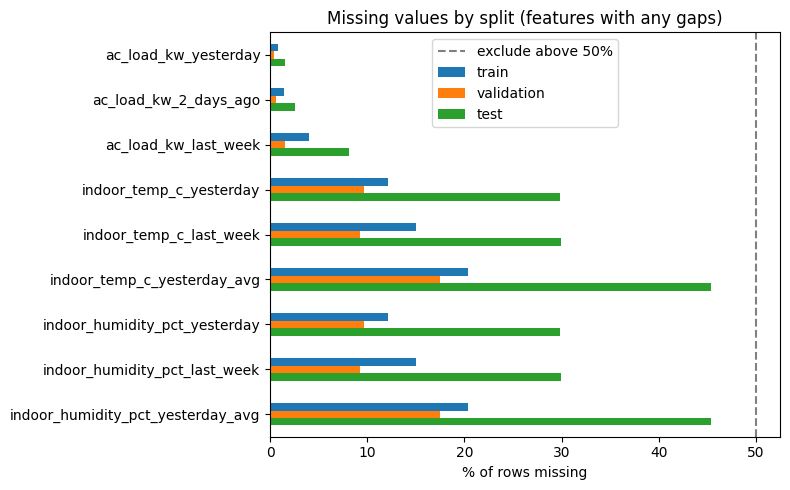

In [4]:
missing = (data.groupby("split")[FEATURES].apply(lambda d: d.isna().mean() * 100).T
           [["train", "validation", "test"]].round(1))
missing["max_gap_vs_train_pp"] = (missing[["validation", "test"]].sub(missing.train, axis=0)).abs().max(axis=1)
display(missing[missing.train.gt(0) | missing.max_gap_vs_train_pp.gt(0)])

ax = missing[["train", "validation", "test"]].loc[lambda m: m.max(axis=1).gt(0)].plot.barh(figsize=(8, 5))
ax.axvline(MAX_MISSING_PCT, ls="--", c="grey", label=f"exclude above {MAX_MISSING_PCT}%")
ax.set(xlabel="% of rows missing", title="Missing values by split (features with any gaps)")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

**Reading the result.**
- Only the lag features have gaps, and nothing comes close to the exclusion threshold in training, so **no feature is excluded for missingness**. The models receive the gaps as missing values rather than filled-in guesses, because LightGBM and XGBoost learn their own handling of missing values.
- **The indoor lags are much patchier in the test period** (Jul–Sep 2018): about 30% missing for the hourly lags and 45% for the daily average, against 12–20% in training. The 2018 sensors had more outages. This doesn't justify excluding them, but it matters for the research question: **at test time, models that rely on indoor features (M2, M4) often have to predict without them.** Keep this in mind when comparing M2 and M4 with M1.

### 2b. Floor 5 zone 1: supply-air sensor

Zones carrying the supply-air flag: ['F5_Z1']


,F5_Z1 mean,F5_Z1 min,other zones mean,other zones min
indoor_temp_c_yesterday,23.7,11.0,25.1,16.1
indoor_temp_c_last_week,23.7,11.0,25.1,16.1
indoor_temp_c_yesterday_avg,23.8,19.5,25.0,19.4
indoor_humidity_pct_yesterday,69.0,47.0,65.4,37.5
indoor_humidity_pct_last_week,69.0,47.0,65.5,37.5
indoor_humidity_pct_yesterday_avg,69.0,49.3,65.5,39.7


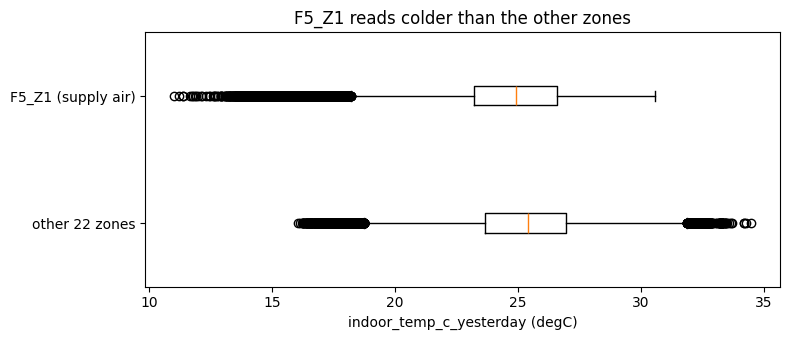

Masked ['indoor_temp_c_yesterday', 'indoor_temp_c_last_week', 'indoor_temp_c_yesterday_avg', 'indoor_humidity_pct_yesterday', 'indoor_humidity_pct_last_week', 'indoor_humidity_pct_yesterday_avg'] on 9,523 F5_Z1 rows


In [5]:
INDOOR = [c for c in FEATURES if GROUP[c] == "indoor"]
f5 = data.supply_air_sensor_flag.eq(1)
print("Zones carrying the supply-air flag:", data.loc[f5, "zone_id"].unique().tolist())

comparison = pd.DataFrame({
    "F5_Z1 mean": data.loc[f5, INDOOR].mean(), "F5_Z1 min": data.loc[f5, INDOOR].min(),
    "other zones mean": data.loc[~f5, INDOOR].mean(), "other zones min": data.loc[~f5, INDOOR].min(),
}).round(1)
display(comparison)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot([data.loc[~f5, "indoor_temp_c_yesterday"].dropna(), data.loc[f5, "indoor_temp_c_yesterday"].dropna()],
           tick_labels=["other 22 zones", "F5_Z1 (supply air)"], vert=False)
ax.set(xlabel="indoor_temp_c_yesterday (degC)", title="F5_Z1 reads colder than the other zones")
plt.tight_layout()
plt.show()

# Mask the indoor readings for this zone (temperature and humidity come from the same S1 sensor)
screened = data.copy()
screened.loc[f5, INDOOR] = np.nan
print(f"Masked {INDOOR} on {f5.sum():,} F5_Z1 rows")

**Reading the result.** F5_Z1 reads about 1.4 °C colder than the other zones on average, and drops to about 11 °C, well below the coldest reading anywhere else (about 16 °C) and below any comfortable room temperature. Its humidity comes from the same sensor, so both are masked. We keep the zone's rows: its AC load, AC lags, calendar and weather features are all still valid. From here on, every check uses the masked data (`screened`).

### 2c. Near-constant features

In [6]:
train_s = screened[screened.split.eq("train")]
top_value = train_s[FEATURES].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100).round(1)
n_unique = train_s[FEATURES].nunique()
constant = pd.DataFrame({"unique_values": n_unique, "top_value_%": top_value}).sort_values("top_value_%", ascending=False)
display(constant.head(8))

,unique_values,top_value_%
is_holiday,2,95.7
rainfall_hourly_mm,61,76.0
is_weekend,2,71.0
ac_load_kw_last_week,31479,66.4
ac_load_kw_yesterday,32422,66.3
ac_load_kw_2_days_ago,32429,66.1
solar_radiation_hourly_wm2,856,46.9
floor,6,18.3


**Reading the result.** No feature is above the threshold. `is_holiday` is the most lopsided (about 96% zeros), but holidays change AC load sharply, so the rare 1s carry real information. `rainfall_hourly_mm` is zero in most hours, which is normal for rain. Neither is excluded.

### 2d. Split coverage: values the training data never saw

In [7]:
CATEGORICAL_LIKE = ["floor", "zone_code", "hour", "weekday", "month", "is_weekend", "is_holiday"]
coverage = []
for c in FEATURES:
    seen = train_s[c].dropna()
    for split in ["validation", "test"]:
        other = screened.loc[screened.split.eq(split), c].dropna()
        if c in CATEGORICAL_LIKE:
            unseen = sorted(set(other.unique()) - set(seen.unique()))
            pct = other.isin(unseen).mean() * 100
            detail = f"unseen values {unseen}" if unseen else ""
        else:
            pct = ((other < seen.min()) | (other > seen.max())).mean() * 100
            detail = f"outside train range {seen.min():.1f} to {seen.max():.1f}" if pct > 0 else ""
        coverage.append({"feature": c, "split": split, "rows_not_covered_%": round(pct, 1), "detail": detail})
coverage = pd.DataFrame(coverage)
display(coverage[coverage["rows_not_covered_%"].gt(0)])

,feature,split,rows_not_covered_%,detail
8,month,validation,100.0,"unseen values [np.int32(4), np.int32(8), np.in..."
9,month,test,33.6,unseen values [np.int32(8)]
24,indoor_temp_c_yesterday_avg,validation,0.3,outside train range 19.4 to 31.7
26,indoor_humidity_pct_yesterday,validation,0.2,outside train range 41.8 to 87.9
28,indoor_humidity_pct_last_week,validation,0.4,outside train range 43.2 to 87.9
30,indoor_humidity_pct_yesterday_avg,validation,2.5,outside train range 49.9 to 82.0
32,outdoor_temp_hourly_c,validation,3.9,outside train range 22.1 to 38.8
34,outdoor_temp_daily_avg_c,validation,7.8,outside train range 25.6 to 32.9
35,outdoor_temp_daily_avg_c,test,1.1,outside train range 25.6 to 32.9
38,outdoor_humidity_daily_avg_pct,validation,7.8,outside train range 53.0 to 90.0


**Reading the result.**
- **`month` is the clear problem.** Training covers only Mar, May, Jun, Jul, Sep, Oct and Nov 2019, because April, August and December were set aside for validation. So 100% of validation rows, and the August third of the test period, have a month value the model never learned from. A tree can only lump months 4, 8 and 12 in with whichever trained months sit next to them, which is a guess. Seasonal effects are better carried by the weather features and the AC lags, which are measured every day. **`month` is excluded.**
- Any small share of weather or indoor values outside the training range is a mild extrapolation. Trees handle that by treating the value like the nearest trained value, so those features are kept.

## Check 3: Redundancy and correlation

**What we check.** Pairs of features that carry the same information.

**Why it matters for tree models.** Trees don't break down when features are correlated, unlike linear regression, so accuracy is rarely the issue. The problems are:
- **Importance gets split.** If two features say the same thing, the model uses each about half the time. Both then look half as important, and a real effect can appear weak in Stage 2.
- **Interpretation suffers.** The research question is whether indoor conditions and weather help. Redundant features make it hard to say which group deserves the credit.
- **No gain.** An exact duplicate adds training time and noise but no information.

**Why Spearman correlation.** It measures whether two features rise and fall together, in a straight line or not. It is also not thrown off by the long tail of zeros in AC load and rainfall, which would distort ordinary (Pearson) correlation.

**Why look at the whole matrix before dropping anything.** Correlation is about pairs, so a feature can only be judged redundant against its partner. Seeing all pairs first lets us drop the feature that is weaker or less meaningful, rather than whichever one we happened to look at first. We also check two kinds of redundancy that correlation can miss:
- features that are **fully determined** by another one (for example, `is_weekend` is just `weekday ≥ 5`);
- a feature mostly explained by the **time of day** (`hour`), measured as the share of its variation that hour-of-day averages explain.

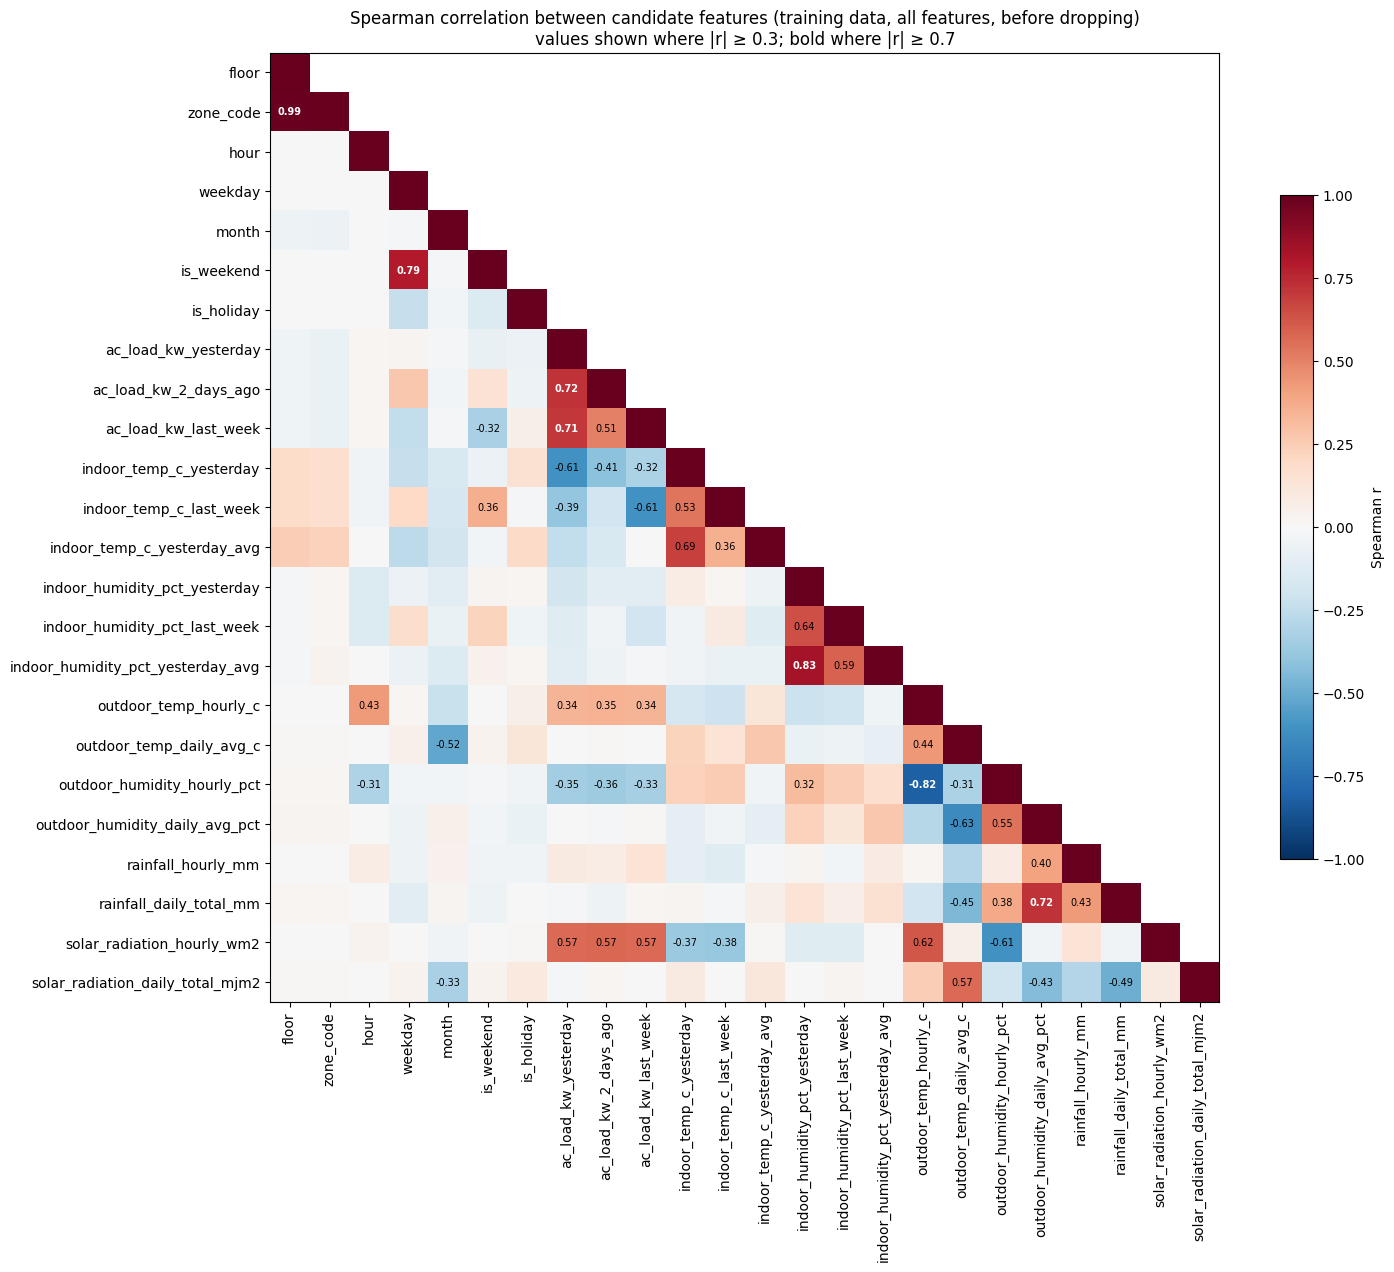

In [8]:
corr = train_s[FEATURES].corr(method="spearman")

fig, ax = plt.subplots(figsize=(15, 12.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)                  # show each pair once
img = ax.imshow(np.ma.masked_where(mask, corr), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(i + 1):
        r = corr.iat[i, j]
        if i != j and abs(r) >= 0.3:
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(r) >= 0.7 else "black",
                    fontweight="bold" if abs(r) >= CORRELATED_R else "normal")
fig.colorbar(img, ax=ax, shrink=0.7, label="Spearman r")
ax.set_title(f"Spearman correlation between candidate features (training data, all features, before dropping)\n"
             f"values shown where |r| ≥ 0.3; bold where |r| ≥ {CORRELATED_R}")
plt.tight_layout()
plt.show()

### Highly correlated pairs

In [9]:
target_r = train_s[FEATURES + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = (upper.stack().rename("spearman_r").reset_index()
         .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs = pairs[pairs.spearman_r.abs().ge(CORRELATED_R)].sort_values("spearman_r", key=abs, ascending=False)
pairs["|r| with target (1 / 2)"] = [f"{abs(target_r[a]):.2f} / {abs(target_r[b]):.2f}"
                                    for a, b in zip(pairs.feature_1, pairs.feature_2)]
pairs["status"] = np.where(pairs.spearman_r.abs().ge(REDUNDANT_R), "redundant", "related, not a duplicate")
display(pairs.reset_index(drop=True))

,feature_1,feature_2,spearman_r,|r| with target (1 / 2),status
0,floor,zone_code,0.986514,0.05 / 0.06,redundant
1,indoor_humidity_pct_yesterday,indoor_humidity_pct_yesterday_avg,0.831249,0.11 / 0.02,"related, not a duplicate"
2,outdoor_temp_hourly_c,outdoor_humidity_hourly_pct,-0.818622,0.34 / 0.34,"related, not a duplicate"
3,weekday,is_weekend,0.794061,0.24 / 0.32,"related, not a duplicate"
4,outdoor_humidity_daily_avg_pct,rainfall_daily_total_mm,0.723840,0.00 / 0.01,"related, not a duplicate"
5,ac_load_kw_yesterday,ac_load_kw_2_days_ago,0.719882,0.72 / 0.50,"related, not a duplicate"
6,ac_load_kw_yesterday,ac_load_kw_last_week,0.706018,0.72 / 0.89,"related, not a duplicate"


### Features fully determined by another feature, or mostly explained by time of day

In [10]:
determined = []
for derived, source in [("floor", "zone_code"), ("is_weekend", "weekday"), ("is_holiday", "weekday")]:
    one_value_each = train_s.groupby(source)[derived].nunique().max() == 1
    determined.append({"feature": derived, "source": source, "fully_determined": one_value_each})
display(pd.DataFrame(determined))

def share_explained_by_hour(col):
    s = train_s[col]
    return 1 - ((s - s.groupby(train_s.hour).transform("mean")) ** 2).sum() / ((s - s.mean()) ** 2).sum()

by_hour = pd.Series({c: share_explained_by_hour(c) for c in FEATURES
                     if c not in CATEGORICAL_LIKE and GROUP[c] == "weather"}).sort_values(ascending=False)
display((100 * by_hour).round(1).to_frame("% of variation explained by hour of day"))

,feature,source,fully_determined
0,floor,zone_code,True
1,is_weekend,weekday,True
2,is_holiday,weekday,False


,% of variation explained by hour of day
solar_radiation_hourly_wm2,90.3
outdoor_temp_hourly_c,66.2
outdoor_humidity_hourly_pct,51.8
rainfall_hourly_mm,3.2
solar_radiation_daily_total_mjm2,0.0
outdoor_humidity_daily_avg_pct,0.0
outdoor_temp_daily_avg_c,0.0
rainfall_daily_total_mm,0.0


**Reading the results and deciding.**
- **`floor` vs `zone_code` (r ≈ 0.99, fully determined).** Each zone sits on exactly one floor, so `floor` adds nothing that `zone_code` doesn't already hold. **`floor` is excluded**; `zone_code` stays because it is the finer of the two.
- **`is_weekend` vs `weekday` (fully determined).** `is_weekend` is exactly `weekday ≥ 5`, which a tree reproduces with a single split. **`is_weekend` is excluded** so weekend effects aren't split across two features. `is_holiday` is *not* determined by weekday (holidays fall on any day), so it stays.
- **Pairs between 0.70 and 0.90** are related but not duplicates, so both features are **kept**:
  - AC lags (yesterday, 2 days ago, last week) overlap because the building repeats its weekly pattern, but each catches different disruptions.
  - Hourly outdoor temperature vs hourly outdoor humidity: hot hours are drier.
  - Daily humidity vs daily rainfall: wet days are humid.
  - Indoor humidity yesterday vs its daily average.

  Each feature in these pairs still carries some information of its own, so neither is a duplicate.
- **Hourly solar radiation** is about 90% explained by hour of day: sunlight follows the clock. It is kept, because the remaining 10% is the weather (cloud cover). When reading its importance later, remember that much of it may be the daily pattern rather than the weather.

## Decision: keep or exclude

A feature is **excluded** if it failed a check that no model can fix: it is leaky, mostly missing, near-constant, never seen in training, or a duplicate of another feature. Every other feature is **kept**.

In [11]:
EXCLUDE = {
    "month": "Check 2d: validation months (Apr, Aug, Dec) never appear in training",
    "floor": "Check 3: fully determined by zone_code (r = 0.99)",
    "is_weekend": "Check 3: fully determined by weekday (weekday >= 5)",
}
over_missing = missing.index[missing.train.gt(MAX_MISSING_PCT)].tolist()
near_constant = constant.index[constant["top_value_%"].gt(MAX_TOP_VALUE_PCT)].tolist()
EXCLUDE.update({c: f"Check 2a: {missing.train[c]:.0f}% missing in training" for c in over_missing})
EXCLUDE.update({c: f"Check 2c: one value covers {constant.loc[c, 'top_value_%']:.0f}% of rows" for c in near_constant})

decision = pd.DataFrame({
    "group": pd.Series(GROUP),
    "decision": ["exclude" if c in EXCLUDE else "keep" for c in GROUP],
    "reason": [EXCLUDE.get(c, "passed all checks") for c in GROUP],
}).loc[FEATURES].rename_axis("feature")

display(decision.style.map(lambda v: "color: #C44E52; font-weight: bold" if v == "exclude" else "",
                           subset=["decision"]))
print(decision.decision.value_counts().to_string())

,group,decision,reason
feature,,,
floor,calendar/zone,exclude,Check 3: fully determined by zone_code (r = 0.99)
zone_code,calendar/zone,keep,passed all checks
hour,calendar/zone,keep,passed all checks
weekday,calendar/zone,keep,passed all checks
month,calendar/zone,exclude,"Check 2d: validation months (Apr, Aug, Dec) never appear in training"
is_weekend,calendar/zone,exclude,Check 3: fully determined by weekday (weekday >= 5)
is_holiday,calendar/zone,keep,passed all checks
ac_load_kw_yesterday,AC lag,keep,passed all checks
ac_load_kw_2_days_ago,AC lag,keep,passed all checks


decision
keep       21
exclude     3


## Drop the excluded features and save

The saved dataset keeps:
- the columns needed to run and score the models: `zone_id`, `timestamp`, `split`, `is_operating_hours`, `day_type` (for baseline B2) and the target `ac_load_kw`;
- every feature labelled **keep**, with the F5_Z1 indoor readings masked.

The saved dictionary adds the keep/exclude decision and reason for every column, and removes the excluded features from the M1–M4 sets, so the modelling notebooks can read their feature lists straight from it.

In [12]:
EXCLUDED = decision.index[decision.decision.eq("exclude")].tolist()
KEPT = decision.index[decision.decision.eq("keep")].tolist()
ID_COLUMNS = ["zone_id", "timestamp", "split", "is_operating_hours", "day_type", TARGET]

screened_out = screened.drop(columns=EXCLUDED)[ID_COLUMNS + KEPT]
screened_out.to_parquet(OUT_DIR / "question_b_model_data_screened.parquet", index=False)

dict_out = dictionary.copy()
dict_out["stage1_decision"] = [decision.decision.get(c, "exclude") for c in dict_out.column]
dict_out["stage1_reason"] = [decision.reason.get(c) if c in decision.index else
                             "not a feature: " + AVAILABILITY[r][1] for c, r in zip(dict_out.column, dict_out.role)]
dict_out.loc[dict_out.column.isin(EXCLUDED), ["M1", "M2", "M3", "M4"]] = np.nan
dict_out.to_csv(OUT_DIR / "question_b_feature_dictionary_screened.csv", index=False)

print(f"Dropped {len(EXCLUDED)} features: {EXCLUDED}")
print(f"Kept {len(KEPT)} of {len(FEATURES)} features")
print(f"Saved {screened_out.shape[0]:,} rows x {screened_out.shape[1]} columns to question_b_model_data_screened.parquet")
print("\nFeatures per model set after screening:")
print(dict_out[["M1", "M2", "M3", "M4"]].eq("Yes").sum().to_string())

Dropped 3 features: ['floor', 'month', 'is_weekend']
Kept 21 of 24 features
Saved 209,119 rows x 27 columns to question_b_model_data_screened.parquet

Features per model set after screening:
M1     7
M2    13
M3    15
M4    21
